# Lab 12-06 · Stability and Frequency Compensation

Companion to [chapter 12-06](../../chapters/12-06-stability-and-compensation.md). Four parts: margins and step responses of an uncompensated three-pole amplifier; phase margin against step overshoot for two-pole loops; Miller compensation of a two-stage amplifier swept over $C_c$; and the nulling resistor. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.optimize import brentq

TP = 2 * math.pi


def poles_T(T0, fps):
    return lambda f: T0 / np.prod([1 + 1j * f / p for p in fps])


def phase(Tf, f, f_lo=1e-3, n=3000):
    fs = np.geomspace(f_lo, f, n)
    return float(np.degrees(np.unwrap(np.angle([Tf(x) for x in fs]))[-1]))


def margins(Tf, lo=1e-3, hi=1e12):
    fc = brentq(lambda f: abs(Tf(f)) - 1, lo, hi, xtol=1e-9, rtol=1e-14)
    return fc, 180 + phase(Tf, fc, lo)


def two_stage(gm1, R1, C1, gm2, R2, CL, Cc, Rz=0.0):
    """Open-loop gain v2/vin of the two-stage amplifier by complex nodal analysis (nodes 1, 2 and, with R_z, m)."""
    def A(f):
        s = 1j * TP * f
        if Rz == 0:
            Y = np.array([[1 / R1 + s * (C1 + Cc), -s * Cc], [gm2 - s * Cc, 1 / R2 + s * (CL + Cc)]])
            b = np.array([-gm1, 0])
        else:
            yc = 1 / (Rz + 1 / (s * Cc))
            Y = np.array([[1 / R1 + s * C1 + yc, -yc], [gm2 - yc, 1 / R2 + s * CL + yc]])
            b = np.array([-gm1, 0])
        return np.linalg.solve(Y, b)[1]
    return A

## Part 1 · An uncompensated three-pole amplifier

$A_0$ = 10⁴ with poles at 1, 10 and 100 MHz (Example 12-06.3). Read the margins at several feedback factors, and simulate the closed-loop step response: the loop is stable only for β below about 0.0122.

beta = 0.001 : GM =   21.74 dB, PM =   54.90 deg at    7.80 MHz
beta = 0.005 : GM =    7.76 dB, PM =   16.32 deg at   21.01 MHz
beta = 0.0122: GM =    0.01 dB, PM =    0.03 deg at   33.29 MHz
beta = 0.02  : GM =   -4.28 dB, PM =   -8.30 deg at   42.33 MHz
beta = 1.0   : GM =  -38.26 dB, PM =  -61.30 deg at  208.03 MHz


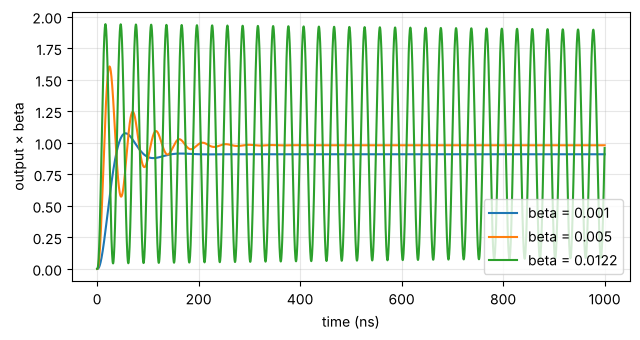

In [2]:
A0, fps = 1e4, [1e6, 10e6, 100e6]
f180 = math.sqrt(1e6 * 10e6 + 1e6 * 100e6 + 10e6 * 100e6)
for beta in [0.001, 0.005, 0.0122, 0.02, 1.0]:
    T = poles_T(A0 * beta, fps)
    fc, pm = margins(T)
    print(f"beta = {beta:<6}: GM = {-20 * math.log10(abs(T(f180))):7.2f} dB, PM = {pm:7.2f} deg at {fc / 1e6:7.2f} MHz")
w = [TP * p for p in fps]
den = np.poly1d([1.0])
for wi in w:
    den = den * np.poly1d([1 / wi, 1])
fig, ax = plt.subplots(figsize=(6.5, 3.5))
t = np.linspace(0, 1e-6, 4001)
for beta in [0.001, 0.005, 0.0122]:
    num = np.poly1d([A0])
    _, y = signal.step(signal.lti(num.coeffs, (den + np.poly1d([A0 * beta])).coeffs), T=t)
    ax.plot(t * 1e9, y * beta, label=f'beta = {beta}')
ax.set_xlabel('time (ns)'); ax.set_ylabel('output × beta'); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Part 2 · Phase margin and overshoot

Two-pole loops $T = \omega_u/[s(1 + s/\omega_2)]$ with $\omega_2/\omega_u$ = 1, 1.5, 2 and 3 (Table 1 of the chapter), in normalized time.

r = 1.0: PM = 51.83 deg, overshoot = 16.30%
r = 1.5: PM = 60.00 deg, overshoot = 8.77%
r = 2.0: PM = 65.53 deg, overshoot = 4.32%
r = 3.0: PM = 72.38 deg, overshoot = 0.43%


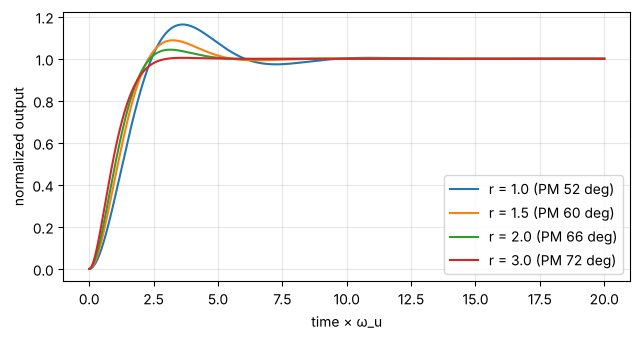

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
t = np.linspace(0, 20, 20001)
for r in [1.0, 1.5, 2.0, 3.0]:
    wc = brentq(lambda x: abs(1 / (1j * x * (1 + 1j * x / r))) - 1, 1e-6, 1e3)
    pm = 180 + np.degrees(np.angle(1 / (1j * wc * (1 + 1j * wc / r))))
    _, y = signal.step(signal.lti([1], [1 / r, 1, 1]), T=t)
    print(f"r = {r}: PM = {pm:.2f} deg, overshoot = {100 * max(y.max() - 1, 0):.2f}%")
    ax.plot(t, y, label=f'r = {r} (PM {pm:.0f} deg)')
ax.set_xlabel('time × ω_u'); ax.set_ylabel('normalized output'); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Part 3 · Miller compensation swept over $C_c$ (the chapter's guided exercise)

Example 12-06.5's amplifier: $g_{m1}$ = 1 mA/V, $R_1$ = 200 kΩ, $C_1$ = 0.2 pF, $g_{m2}$ = 10 mA/V, $R_2$ = 50 kΩ, $C_L$ = 5 pF. **Predict first:** halving $C_c$ from 1.1 to 0.55 pF doubles the estimated GBW. Does the crossover double? What happens to the phase margin?

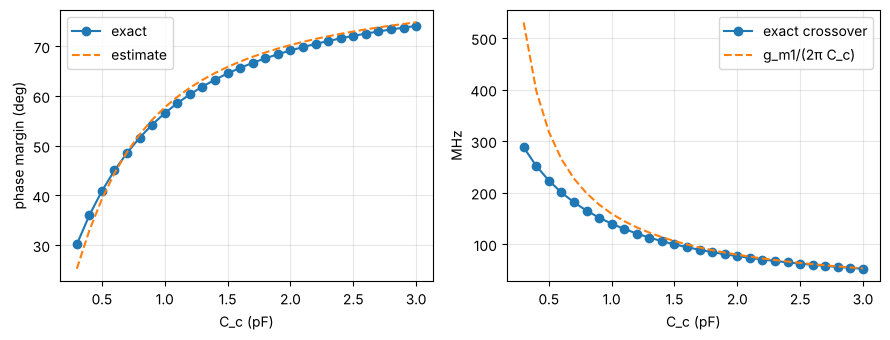

C_c = 1.10 pF: GBW estimate 144.7 MHz, crossover 129.5 MHz, PM 58.56 deg
C_c = 0.55 pF: GBW estimate 289.4 MHz, crossover 211.4 MHz, PM 43.06 deg


In [4]:
gm1, R1, C1, gm2, R2, CL = 1e-3, 200e3, 0.2e-12, 10e-3, 50e3, 5e-12
ccs = np.linspace(0.3e-12, 3e-12, 28)
exact = np.array([margins(two_stage(gm1, R1, C1, gm2, R2, CL, c)) for c in ccs])
est = 90 - np.degrees(np.arctan((gm1 / ccs) / (gm2 / CL))) - np.degrees(np.arctan(gm1 / gm2))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(ccs * 1e12, exact[:, 1], 'o-', label='exact'); ax[0].plot(ccs * 1e12, est, '--', label='estimate')
ax[0].set_xlabel('C_c (pF)'); ax[0].set_ylabel('phase margin (deg)'); ax[0].grid(True, alpha=0.3); ax[0].legend()
ax[1].plot(ccs * 1e12, exact[:, 0] / 1e6, 'o-', label='exact crossover')
ax[1].plot(ccs * 1e12, gm1 / (TP * ccs) / 1e6, '--', label='g_m1/(2π C_c)')
ax[1].set_xlabel('C_c (pF)'); ax[1].set_ylabel('MHz'); ax[1].grid(True, alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()
for c in (1.1e-12, 0.55e-12):
    fc, pm = margins(two_stage(gm1, R1, C1, gm2, R2, CL, c))
    print(f"C_c = {c * 1e12:.2f} pF: GBW estimate {gm1 / (TP * c) / 1e6:.1f} MHz, crossover {fc / 1e6:.1f} MHz, PM {pm:.2f} deg")

## Part 4 · The nulling resistor

Sweep $R_z$ in series with the 1.1 pF capacitor from 0 to 1 kΩ. At 100 Ω the zero is gone; at 554.5 Ω it cancels $p_2$; beyond that it becomes a left-half-plane zero below $p_2$ that adds lead and raises the crossover toward the new pole at about $1/(R_zC_1)$.

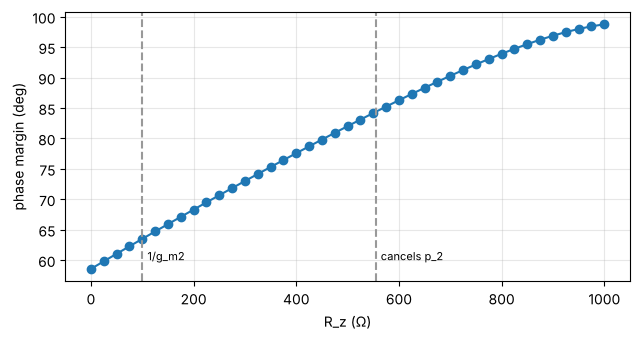

R_z = 1 kΩ: PM = 98.75 deg, crossover 202.4 MHz; third pole near 796 MHz


In [5]:
rz = np.linspace(0, 1000, 41)
res = np.array([margins(two_stage(gm1, R1, C1, gm2, R2, CL, 1.1e-12, Rz=x)) for x in rz])
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(rz, res[:, 1], 'o-')
for x, lab in ((1 / gm2, '1/g_m2'), ((1 + CL / 1.1e-12) / gm2, 'cancels p_2')):
    ax.axvline(x, color='0.6', ls='--'); ax.text(x + 10, 60, lab, fontsize=8)
ax.set_xlabel('R_z (Ω)'); ax.set_ylabel('phase margin (deg)'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
fc, pm = margins(two_stage(gm1, R1, C1, gm2, R2, CL, 1.1e-12, Rz=1000.0))
print(f"R_z = 1 kΩ: PM = {pm:.2f} deg, crossover {fc / 1e6:.1f} MHz; third pole near {1 / (TP * 1000 * C1) / 1e6:.0f} MHz")

**Discussion.** A phase margin above 90° is not "better than perfect": the left-half-plane zero now sits below the old $p_2$ and lifts the gain, pushing the crossover up toward the third pole created by $R_z$ and $C_1$, and a pole–zero pair that does not cancel exactly leaves a slow settling tail. Designers aim the zero near or slightly above $p_2$.